Decision Tree Titanic Task

In [1]:
# import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

titanic_df = pd.read_csv('titanic.csv')
titanic_df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
# Data cleaning and preprocessing
titanic_df = titanic_df.drop(columns=['Cabin'], errors='ignore')
titanic_df['Age'] = titanic_df['Age'].fillna(titanic_df['Age'].median())
titanic_df['Embarked'] = titanic_df['Embarked'].fillna(titanic_df['Embarked'].mode()[0])

# Drop identities / non-predictive test fields
titanic_df = titanic_df.drop(columns=['PassengerId','Name','Ticket'], errors='ignore')

# One-hot encoding with drop_first=True to avoid the dummy variable trap
titanic_df = pd.get_dummies(titanic_df, columns=['Sex', 'Embarked'], drop_first=True)

titanic_df.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [4]:
# Feature and target
X = titanic_df.drop('Survived', axis=1)
y = titanic_df['Survived']

# Train/dev/test split: 60/20/20
X_train, X_temp, y_train, y_temp = train_test_split(X,
                                                    y, test_size=0.4, random_state=42, stratify=y)

X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(X_train.shape, X_dev.shape, X_test.shape)


(534, 8) (178, 8) (179, 8)


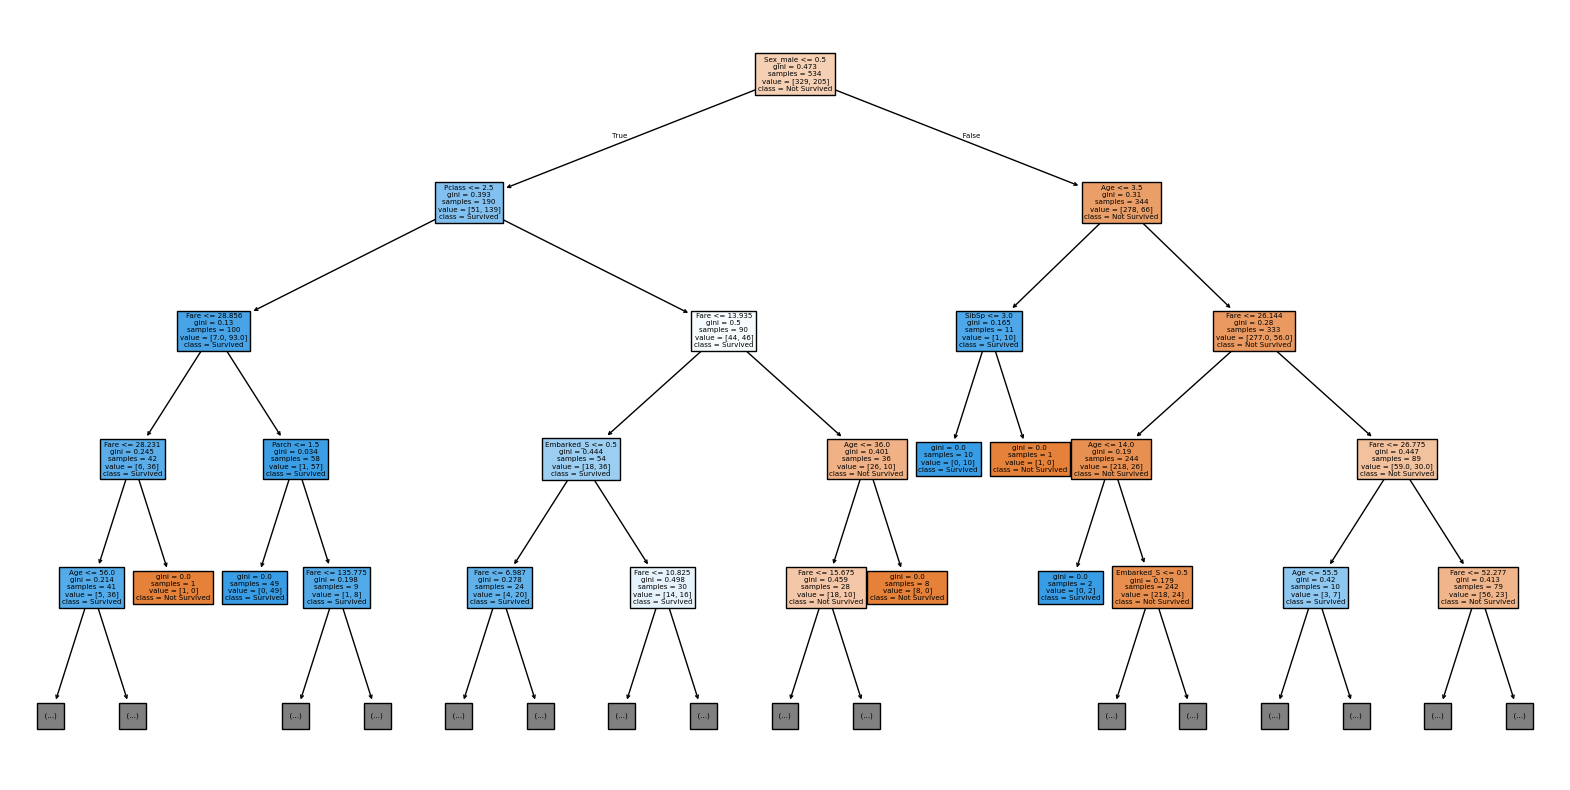

Development Accuracy: 0.7528089887640449


In [8]:
# Unrestricted decision tree
tree_unrestricted = DecisionTreeClassifier(random_state=42)
tree_unrestricted.fit(X_train, y_train)

plt.figure(figsize=(20,10))
plot_tree(tree_unrestricted, feature_names=X.columns,
         class_names=['Not Survived','Survived'],
         filled=True, max_depth=4)
plt.show()

dev_accuracy = accuracy_score(y_dev, tree_unrestricted.predict(X_dev))
print('Development Accuracy:', dev_accuracy)




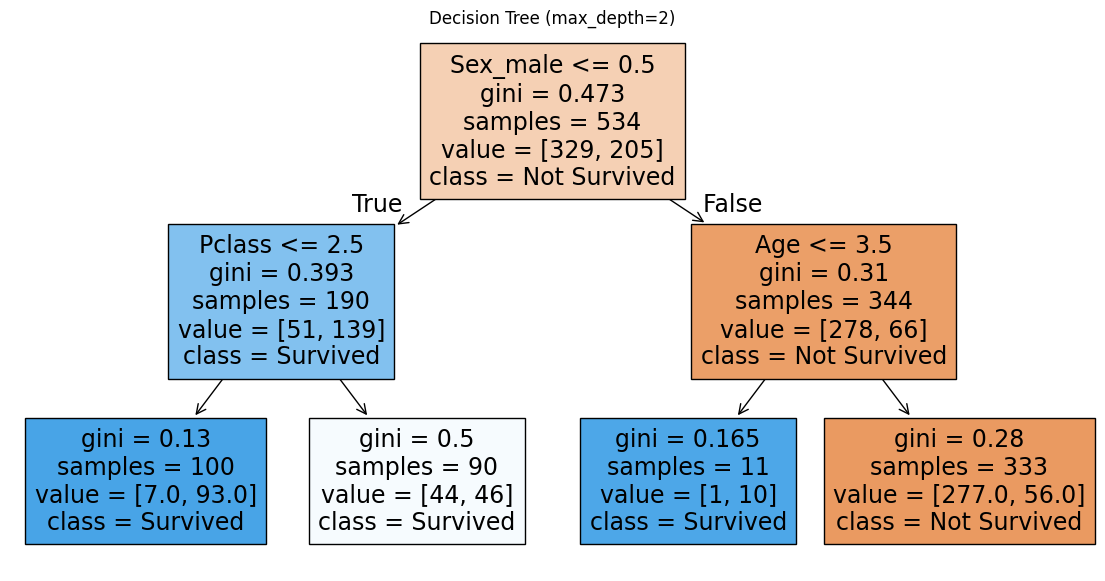

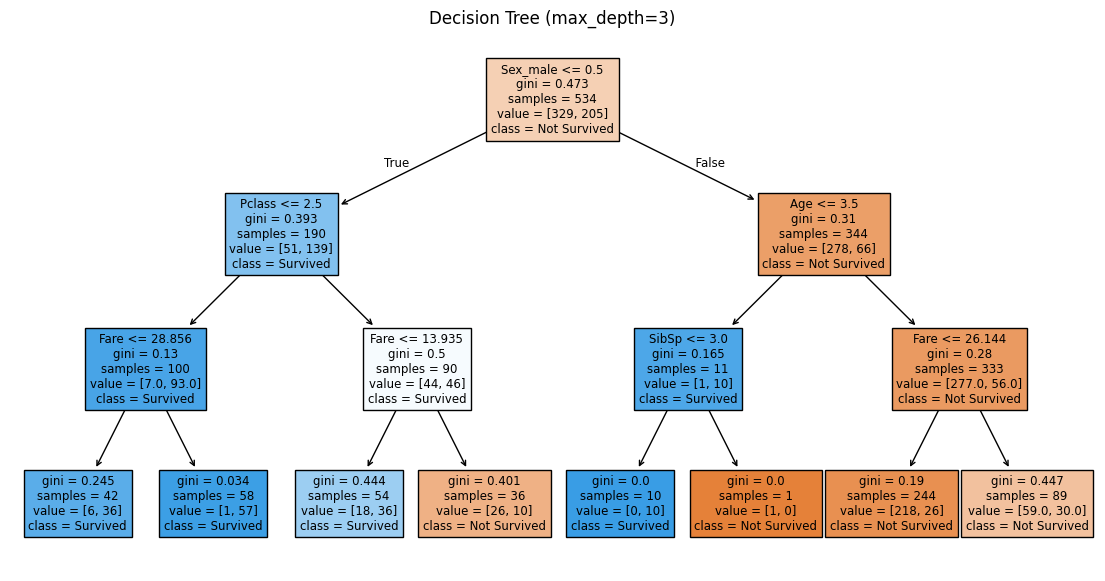

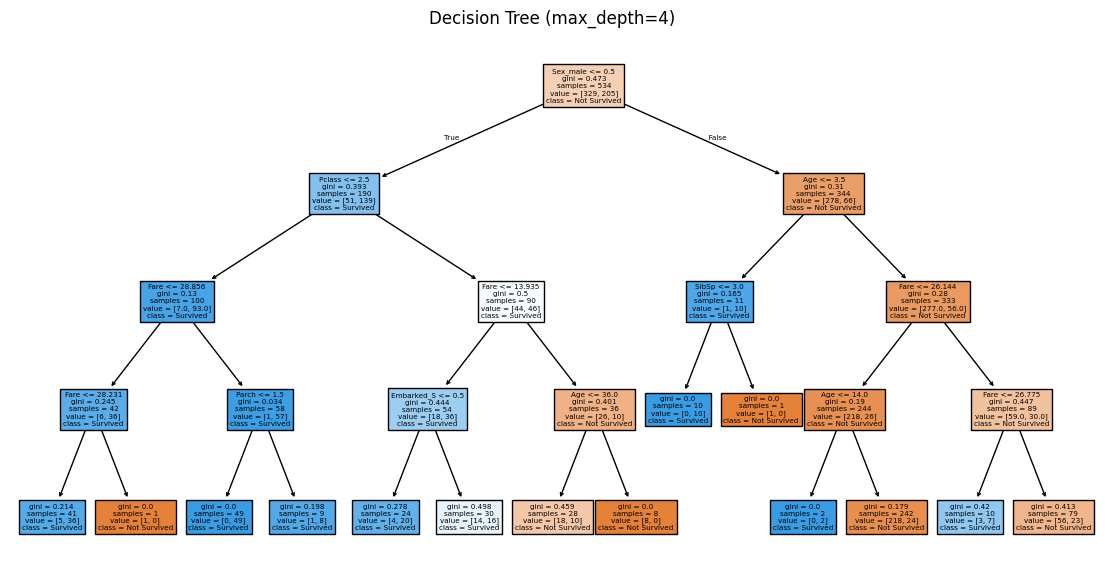

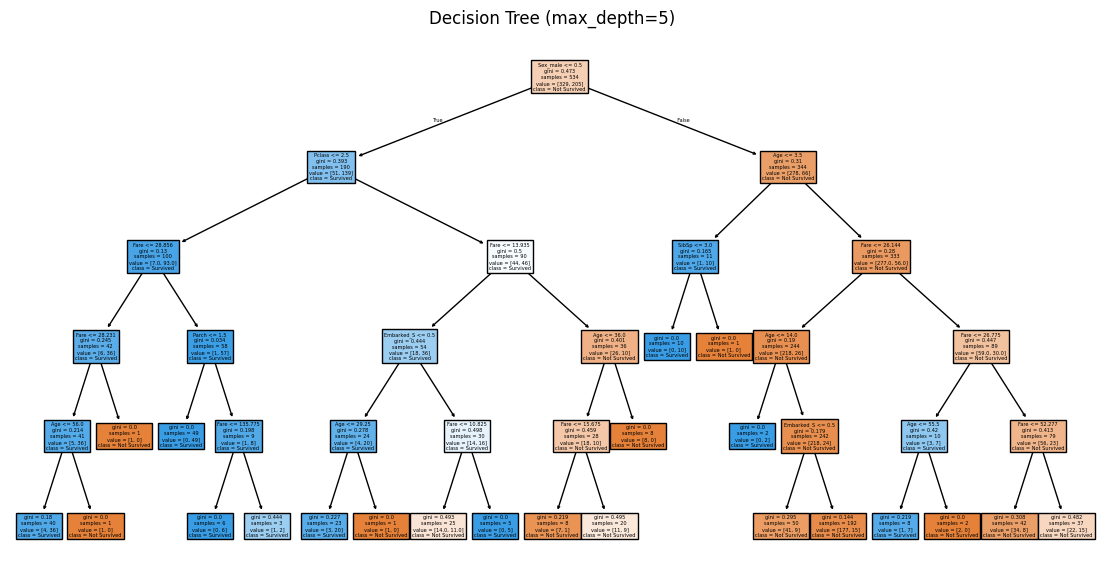

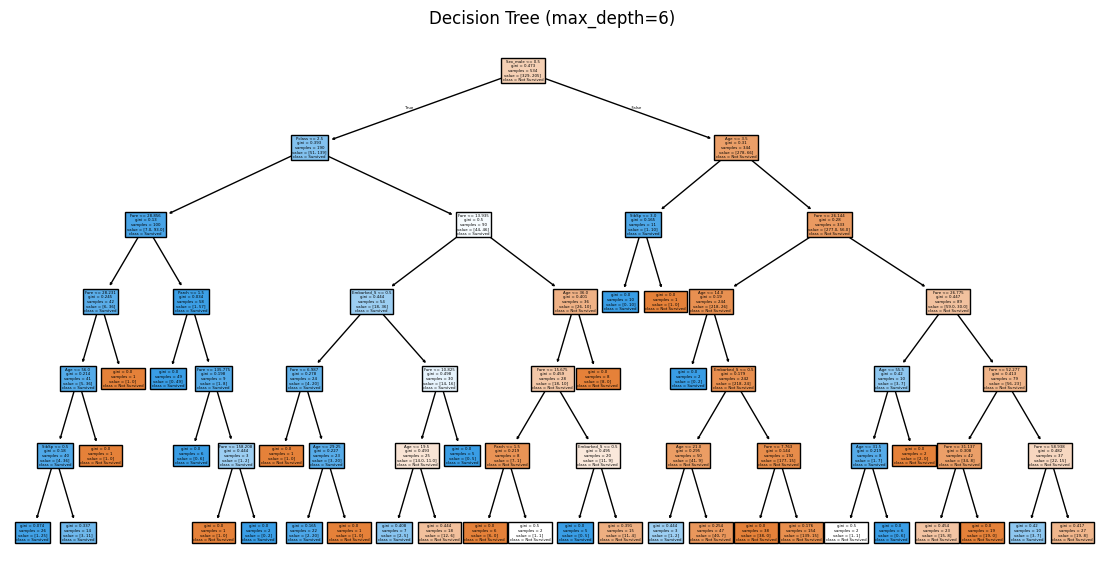

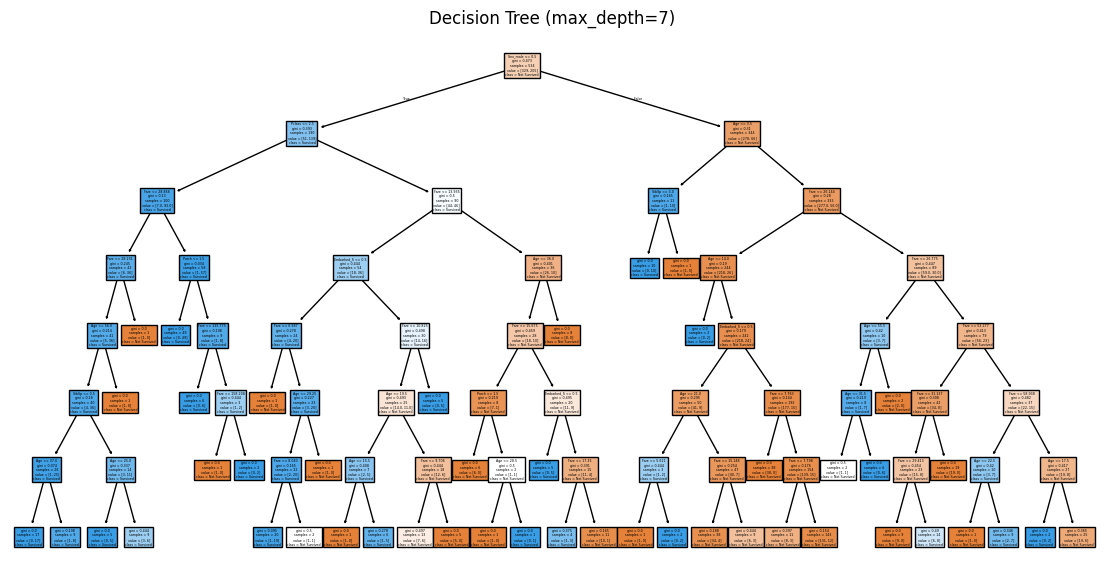

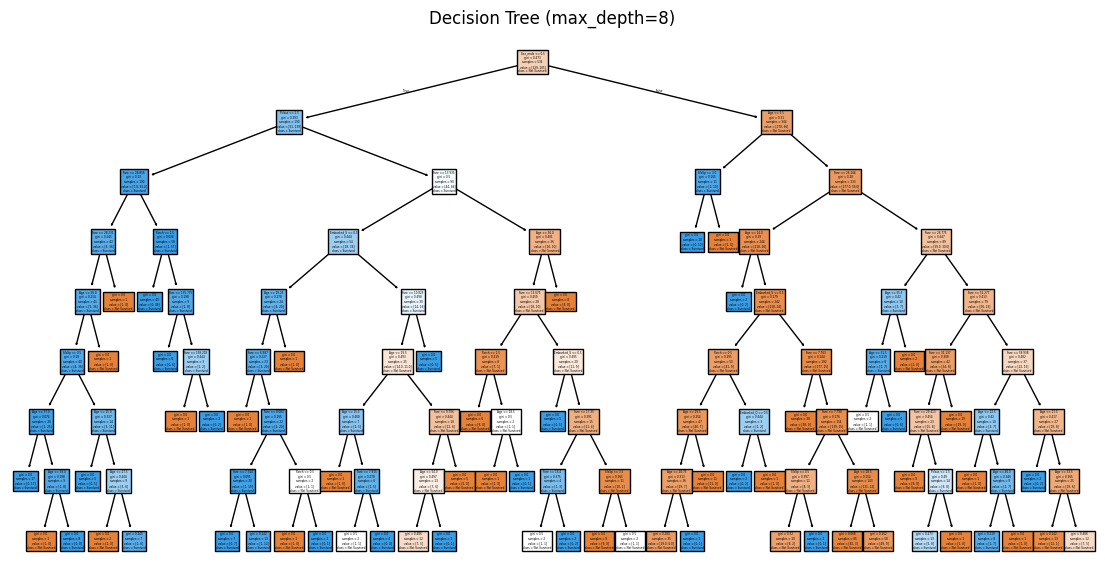

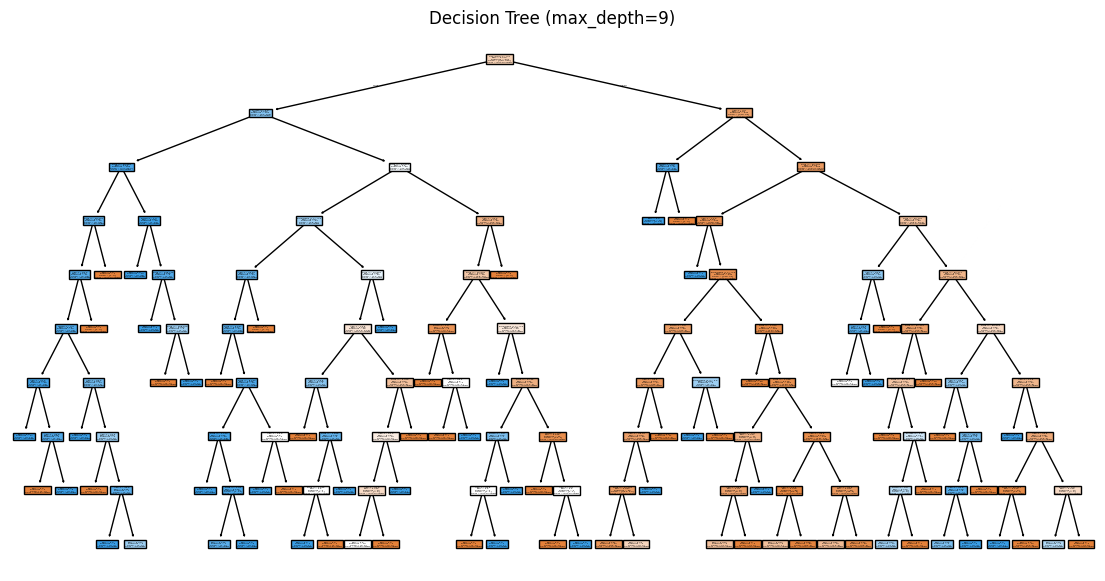

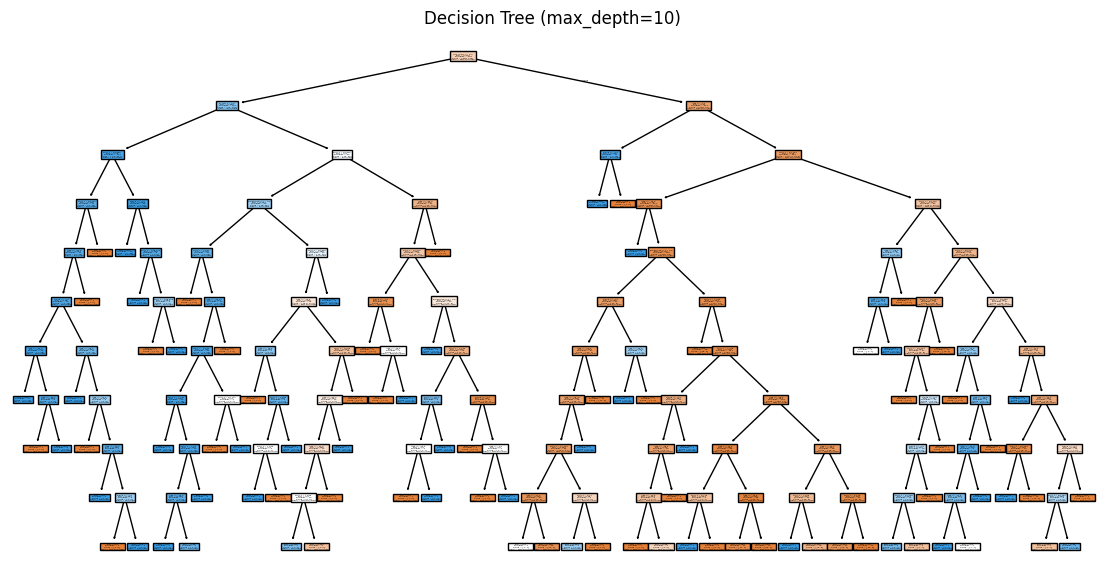

,max_depth,train_accuracy,dev_accuracy
0,2,0.797753,0.797753
1,3,0.829588,0.808989
2,4,0.842697,0.808989
3,5,0.855805,0.814607
4,6,0.883895,0.797753
5,7,0.902622,0.803371
6,8,0.919476,0.797753
7,9,0.932584,0.775281
8,10,0.947566,0.786517


In [9]:
# Train trees with max_depth from 2 to 10
depths = range(2, 11)
train_accs = []
dev_accs = []

for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    model.fit(X_train, y_train)

    train_accs.append(accuracy_score(y_train, model.predict(X_train)))
    dev_accs.append(accuracy_score(y_dev, model.predict(X_dev)))

    plt.figure(figsize=(14,7))
    plot_tree(model, feature_names=X.columns,
              class_names=['Not Survived', 'Survived'],
              filled=True)
    plt.title(f'Decision Tree (max_depth={depth})')
    plt.show()

results = pd.DataFrame({
    'max_depth': list(depths),
    'train_accuracy': train_accs,
    'dev_accuracy': dev_accs
})
results

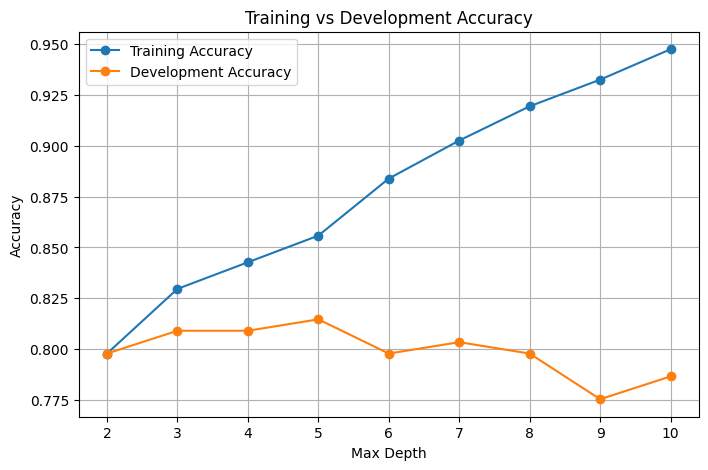

,max_depth,train_accuracy,dev_accuracy
0,2,0.797753,0.797753
1,3,0.829588,0.808989
2,4,0.842697,0.808989
3,5,0.855805,0.814607
4,6,0.883895,0.797753
5,7,0.902622,0.803371
6,8,0.919476,0.797753
7,9,0.932584,0.775281
8,10,0.947566,0.786517


In [10]:
# Accuracy comparison graph
plt.figure(figsize=(8,5))
plt.plot(list(depths), train_accs, marker='o', label='Training Accuracy')
plt.plot(list(depths), dev_accs, marker='o', label='Development Accuracy')
plt.xlabel('Max Depth')
plt.ylabel('Accuracy')
plt.title('Training vs Development Accuracy')
plt.legend()
plt.grid(True)
plt.show()

results

In [12]:
# Final model using optimal depth
optimal_depth = 5

final_model = DecisionTreeClassifier(max_depth=optimal_depth, random_state=42)
final_model.fit(X_train, y_train)

test_accuracy = accuracy_score(y_test, final_model.predict(X_test))
print('Optimal Depth:', optimal_depth)
print('Test Accuracy:', test_accuracy)

Optimal Depth: 5
Test Accuracy: 0.8212290502793296
